## EDA on Datasets for Tilburg University


Datasets

https://www.kaggle.com/datasets/nidhekshaa/fake-profile-detection-dataset/data?select=Instagram.csv

https://www.tapadhirdas.com/das-lab/datasets/limfadd


### The 4 V's Assessment

#### **1. Volume**
- **Dataset Scale:** 5,000 rows × 13 columns (~508 KB)
- **Memory Footprint:** Light dataset that easily fits entirely into memory for rapid analysis, experimentation, and model training.

#### **2. Velocity**
- **Current Dataset:** Static batch dataset without temporal or timestamp features (no account creation dates, activity intervals, or event streams).
- **Production Context:** High velocity in real-world deployment (Instagram accounts are created, active, modified, and banned at massive scale per second, demanding low-latency inference pipelines).

#### **3. Variety**
Structured tabular data featuring a rich mix of numerical ratios, count metrics, and binary profile indicators:

* **Numerical & Count Features:**
  - `nums/length username` (Ratio of numerical digits to username character length)
  - `fullname words` (Number of words in full name)
  - `nums/length fullname` (Ratio of digits to full name character length)
  - `description length` (Bio character count)
  - `#posts` (Total number of posts)
  - `#followers` (Total follower count)
  - `#follows` (Total following count)
  - `followers_following_ratio` (Followers divided by following ratio)

* **Binary Indicator Features:**
  - `profile pic` (1 = Profile picture present, 0 = Missing)
  - `name==username` (1 = Full name identical to username, 0 = Different)
  - `external URL` (1 = External link present in bio, 0 = None)
  - `private` (1 = Private account, 0 = Public account)

* **Target Classification Label:**
  - `fake` (Binary ground truth: `0` = Genuine / Real Account, `1` = Fake / Fraudulent Account)

#### **4. Veracity**
- **Ground Truth Quality:** Balanced distribution with an equal split of 2,500 real accounts (50%) and 2,500 fake accounts (50%), sourced from Kaggle (`nidhekshaa/fake-profile-detection-dataset`).
- **Data Integrity & Consistency:**
  - **No Missing Values:** Clean tabular structure with 0 null values across all 13 columns.
  - **Duplicate Rows:** Contains 66 exact duplicate rows in the raw dataset.
  - **Zero-Division Imputation in Ratios:** When `#follows == 0`, the pre-computed `followers_following_ratio` was assigned the raw `#followers` value (or 0 if followers is also 0) rather than raising division errors.
  - **Extreme Skewness & Outliers:** `#followers` ranges from 0 to 15,338,538 (mean 102,393 for genuine accounts vs 96 for fake accounts; medians: 651 vs 42). This extreme right-skew requires logarithmic scaling for visual analysis and feature normalization during modeling.
  - **Distinctive Domain Separators:**
    - `external URL`: 0.00% of fake accounts have an external URL (compared to ~9.92% of real accounts).
    - `profile pic`: ~78.6% of fake accounts lack a profile picture, compared to only ~1.7% of real accounts.
    - **Zero Posts:** 53.4% of fake accounts have 0 posts, compared to only 0.52% of real accounts.

> **Dataset Comparison & Generalization Context**
> Unlike the LIMFADD dataset (which contains multi-class synthetic LLM expansions across Bot, Scam, Spam, and Real), this Kaggle Instagram dataset represents binary real-world scraped Instagram profiles. Evaluating models across both datasets offers a robust comparison between synthetic multi-class behavior (LIMFADD) and empirical real-world binary profile markers (Kaggle Instagram).


### 4 V's Assessment Summary

| Dimension | Current Dataset | Production & Feature Breakdown |
| :--- | :--- | :--- |
| **Volume** | **5,000 rows** × **13 columns** (508 KB) | Low volume; easily fits into memory for single-node processing and fast model training. |
| **Velocity** | Static snapshot (no timestamps) | High velocity in live production due to continuous account registrations, automated bot creation, and real-time banning. |
| **Variety** | Structured tabular dataset | **Numerical:** `nums/length username`, `fullname words`, `nums/length fullname`, `description length`, `#posts`, `#followers`, `#follows`, `followers_following_ratio`<br>**Binary Flags:** `profile pic`, `name==username`, `external URL`, `private`<br>**Target Label:** `fake` (0 = Real, 1 = Fake) |
| **Veracity** | High label balance (2,500 real / 2,500 fake)<br>**Data Nuances:** Clean data (0 nulls), 66 duplicate rows, extreme right-skew in `#followers` (max 15.3M), ratio imputation on zero follows | Real scraped Instagram profile characteristics.<br> *Acts as an empirical benchmark against synthetic datasets like LIMFADD.* |


In [1]:
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_csv(r"..\Datasets\Kaggle datasets\Instagram.csv")

In [3]:
df.head()

Out[0]: 
   profile pic  nums/length username  ...  fake  followers_following_ratio
0            1                  0.27  ...     0                   1.046025
1            1                  0.00  ...     0                   5.131086
2            1                  0.10  ...     0                   1.606061
3            1                  0.00  ...     0                   0.634969
4            1                  0.00  ...     0                   1.188976

[5 rows x 13 columns]


,profile pic,nums/length username,fullname words,nums/length fullname,name==username,description length,external URL,private,#posts,#followers,#follows,fake,followers_following_ratio
0,1,0.27,0,0.0,0,53,0,0,32,1000,955,0,1.046025
1,1,0.00,2,0.0,0,44,0,0,286,2740,533,0,5.131086
2,1,0.10,2,0.0,0,0,0,1,13,159,98,0,1.606061
3,1,0.00,1,0.0,0,82,0,0,679,414,651,0,0.634969
4,1,0.00,2,0.0,0,0,0,1,6,151,126,0,1.188976


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   profile pic                5000 non-null   int64  
 1   nums/length username       5000 non-null   float64
 2   fullname words             5000 non-null   int64  
 3   nums/length fullname       5000 non-null   float64
 4   name==username             5000 non-null   int64  
 5   description length         5000 non-null   int64  
 6   external URL               5000 non-null   int64  
 7   private                    5000 non-null   int64  
 8   #posts                     5000 non-null   int64  
 9   #followers                 5000 non-null   int64  
 10  #follows                   5000 non-null   int64  
 11  fake                       5000 non-null   int64  
 12  followers_following_ratio  5000 non-null   float64
dtypes: float64(3), int64(10)
memory usage: 507.9 KB


#### Check label balance


In [5]:
df["fake"].value_counts()

Out[0]: 
fake
0    2500
1    2500
Name: count, dtype: int64


fake
0    2500
1    2500
Name: count, dtype: int64

In [6]:
df.shape

Out[0]: (5000, 13)


(5000, 13)

In [7]:
df.describe()

Out[0]: 
       profile pic  nums/length username  ...        fake  followers_following_ratio
count  5000.000000           5000.000000  ...  5000.00000               5.000000e+03
mean      0.598200              0.166175  ...     0.50000               1.317392e+03
std       0.490311              0.194733  ...     0.50005               2.920581e+04
min       0.000000              0.000000  ...     0.00000               0.000000e+00
25%       0.000000              0.000000  ...     0.00000               3.636364e-01
50%       1.000000              0.089193  ...     0.50000               7.959259e-01
75%       1.000000              0.300410  ...     1.00000               1.697607e+00
max       1.000000              0.920000  ...     1.00000               1.377524e+06

[8 rows x 13 columns]


,profile pic,nums/length username,fullname words,nums/length fullname,name==username,description length,external URL,private,#posts,#followers,#follows,fake,followers_following_ratio
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03,5000.000000,5000.00000,5.000000e+03
mean,0.598200,0.166175,1.212800,0.036068,0.007600,20.997200,0.049600,0.227800,103.331400,5.124435e+04,481.381800,0.50000,1.317392e+03
std,0.490311,0.194733,0.890435,0.106235,0.086855,33.234706,0.217139,0.419455,377.804886,5.963749e+05,761.530132,0.50005,2.920581e+04
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.00000,0.000000e+00
25%,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000e+01,58.000000,0.00000,3.636364e-01
50%,1.000000,0.089193,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,10.000000,1.450000e+02,242.000000,0.50000,7.959259e-01
75%,1.000000,0.300410,2.000000,0.000000,0.000000,31.250000,0.000000,0.000000,81.000000,6.960000e+02,591.000000,1.00000,1.697607e+00
max,1.000000,0.920000,12.000000,1.000000,1.000000,150.000000,1.000000,1.000000,7389.000000,1.533854e+07,7500.000000,1.00000,1.377524e+06


#### Inspect ratio distributions and zero-division handling in pre-computed ratios


In [8]:
# Inspect how followers_following_ratio behaves when #follows is 0
zero_follows = df[df['#follows'] == 0][['#followers', '#follows', 'followers_following_ratio']]
print(f"Number of accounts with 0 follows: {len(zero_follows)}")
zero_follows.head(10)

Number of accounts with 0 follows: 103
Out[0]: 
     #followers  #follows  followers_following_ratio
45       380510         0                   380510.0
301           0         0                        0.0
339           0         0                        0.0
345           2         0                        2.0
391           0         0                        0.0
488          49         0                       49.0
492          10         0                       10.0
496          16         0                       16.0
498          86         0                       86.0
516          21         0                       21.0


,#followers,#follows,followers_following_ratio
45,380510,0,380510.0
301,0,0,0.0
339,0,0,0.0
345,2,0,2.0
391,0,0,0.0
488,49,0,49.0
492,10,0,10.0
496,16,0,16.0
498,86,0,86.0
516,21,0,21.0


#### Standardize and inspect binary / categorical features


In [9]:
binary_cols = ['profile pic', 'name==username', 'external URL', 'private', 'fake']
for col in binary_cols:
    print(f"{col}: unique values = {df[col].unique()}")

profile pic: unique values = [1 0]
name==username: unique values = [0 1]
external URL: unique values = [0 1]
private: unique values = [0 1]
fake: unique values = [0 1]


In [10]:
# Check data types of all columns
print(df.dtypes)

profile pic                    int64
nums/length username         float64
fullname words                 int64
nums/length fullname         float64
name==username                 int64
description length             int64
external URL                   int64
private                        int64
#posts                         int64
#followers                     int64
#follows                       int64
fake                           int64
followers_following_ratio    float64
dtype: object


In [11]:
print("Missing values per column:\n", df.isnull().sum())

Missing values per column:
 profile pic                  0
nums/length username         0
fullname words               0
nums/length fullname         0
name==username               0
description length           0
external URL                 0
private                      0
#posts                       0
#followers                   0
#follows                     0
fake                         0
followers_following_ratio    0
dtype: int64


In [12]:
print("Duplicate rows count:", df.duplicated().sum())

Duplicate rows count: 66


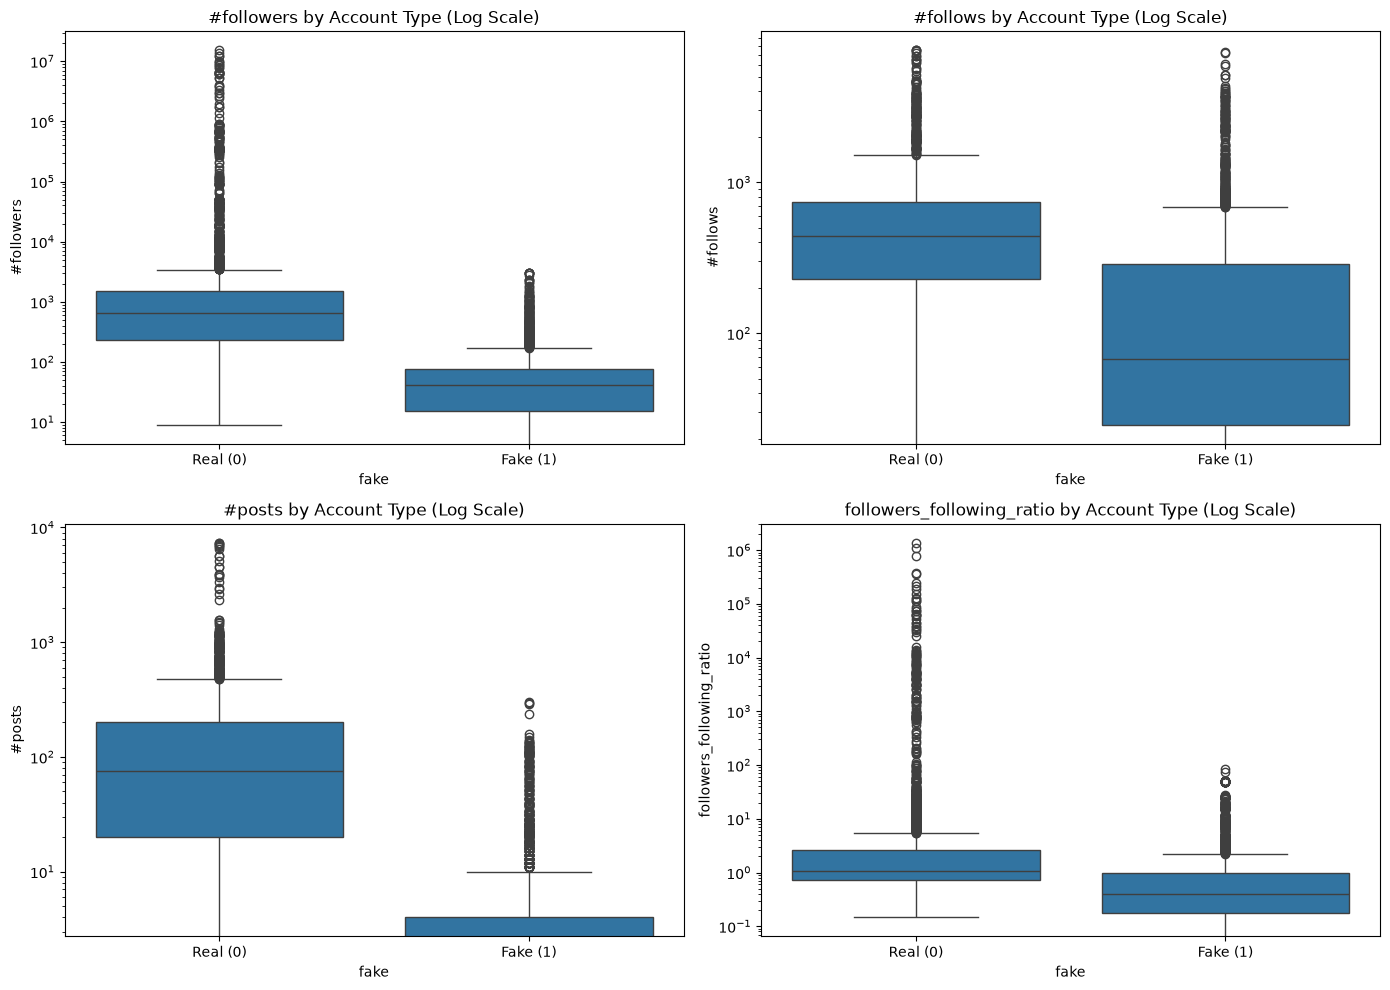

In [13]:
num_cols = ['#followers', '#follows', '#posts', 'followers_following_ratio']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flatten(), num_cols):
    sn.boxplot(data=df, x='fake', y=col, ax=ax)
    ax.set_yscale('log') # Log scale handles the extreme skewness
    ax.set_title(f'{col} by Account Type (Log Scale)')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Real (0)', 'Fake (1)'])
plt.tight_layout()
plt.show()

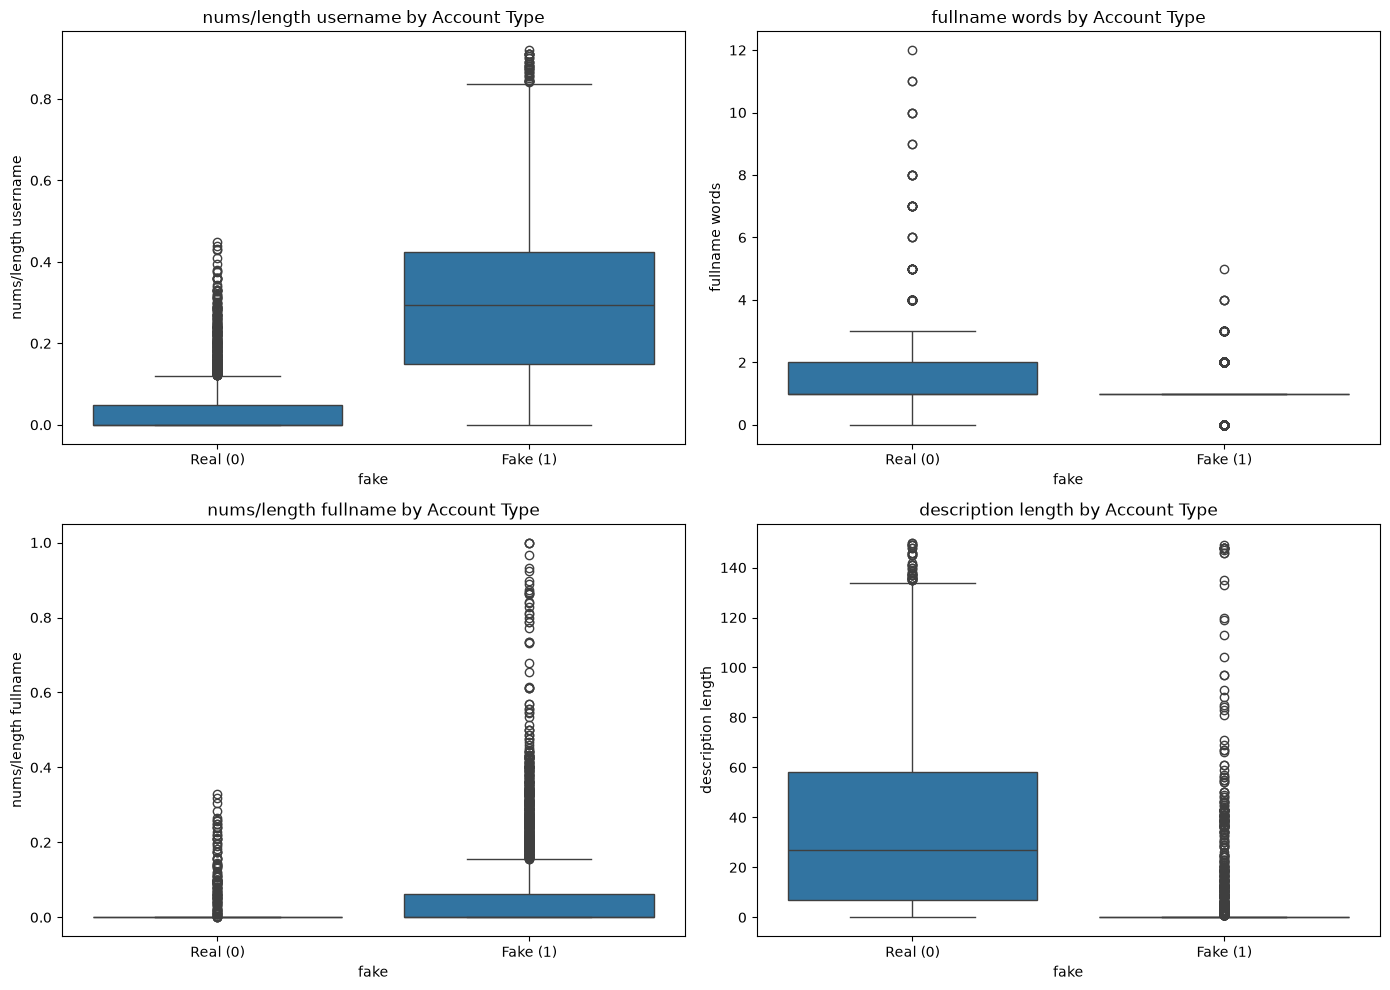

In [14]:
# Profile metadata features: username digits ratio and description length
metadata_cols = ['nums/length username', 'fullname words', 'nums/length fullname', 'description length']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flatten(), metadata_cols):
    sn.boxplot(data=df, x='fake', y=col, ax=ax)
    ax.set_title(f'{col} by Account Type')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Real (0)', 'Fake (1)'])
plt.tight_layout()
plt.show()


--- profile pic (% within each label) ---
             Real (0)  Fake (1)
profile pic                    
0                1.72     78.64
1               98.28     21.36

--- external URL (% within each label) ---
              Real (0)  Fake (1)
external URL                    
0                90.08     100.0
1                 9.92       0.0

--- private (% within each label) ---
         Real (0)  Fake (1)
private                    
0            75.6     78.84
1            24.4     21.16

--- name==username (% within each label) ---
                Real (0)  Fake (1)
name==username                    
0                  99.96     98.52
1                   0.04      1.48


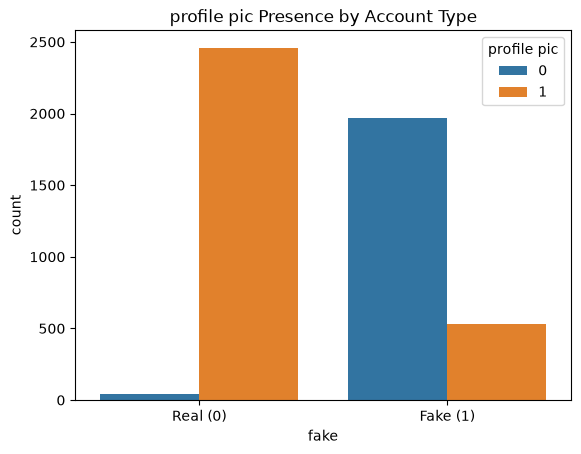

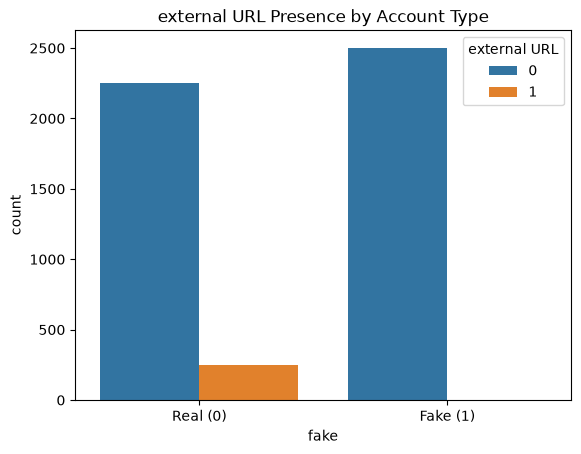

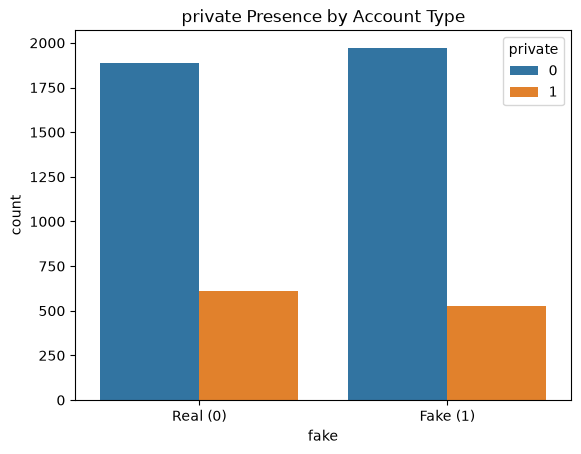

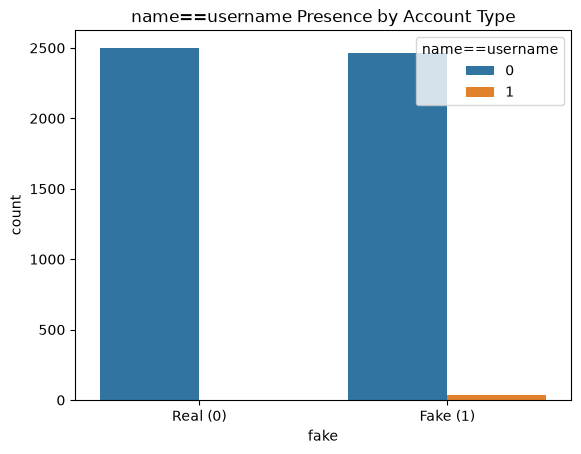

In [15]:
for col in ['profile pic', 'external URL', 'private', 'name==username']:
    ct = pd.crosstab(df[col], df['fake'], normalize='columns') * 100
    print(f"\n--- {col} (% within each label) ---")
    ct.columns = ['Real (0)', 'Fake (1)']
    print(ct.round(2))

    # Visualizing proportion across account types
    sn.countplot(data=df, x='fake', hue=col)
    plt.title(f'{col} Presence by Account Type')
    plt.xticks([0, 1], ['Real (0)', 'Fake (1)'])
    plt.show()

In [16]:
# Percentage of zero posts across labels
zero_posts = df.groupby('fake')['#posts'].apply(lambda x: (x == 0).mean() * 100)
print("Percentage of accounts with 0 Posts:\n", zero_posts.round(2))

# Percentage of zero description length (no bio) across labels
zero_bio = df.groupby('fake')['description length'].apply(lambda x: (x == 0).mean() * 100)
print("\nPercentage of accounts with 0 Description Length (No Bio):\n", zero_bio.round(2))

# Percentage of zero profile pictures across labels
zero_pic = df.groupby('fake')['profile pic'].apply(lambda x: (x == 0).mean() * 100)
print("\nPercentage of accounts with 0 (No) Profile Picture:\n", zero_pic.round(2))

# Percentage of zero external URL across labels
zero_url = df.groupby('fake')['external URL'].apply(lambda x: (x == 0).mean() * 100)
print("\nPercentage of accounts with 0 (No) External URL:\n", zero_url.round(2))

Percentage of accounts with 0 Posts:
 fake
0     0.52
1    53.40
Name: #posts, dtype: float64

Percentage of accounts with 0 Description Length (No Bio):
 fake
0    15.84
1    83.32
Name: description length, dtype: float64

Percentage of accounts with 0 (No) Profile Picture:
 fake
0     1.72
1    78.64
Name: profile pic, dtype: float64

Percentage of accounts with 0 (No) External URL:
 fake
0     90.08
1    100.00
Name: external URL, dtype: float64


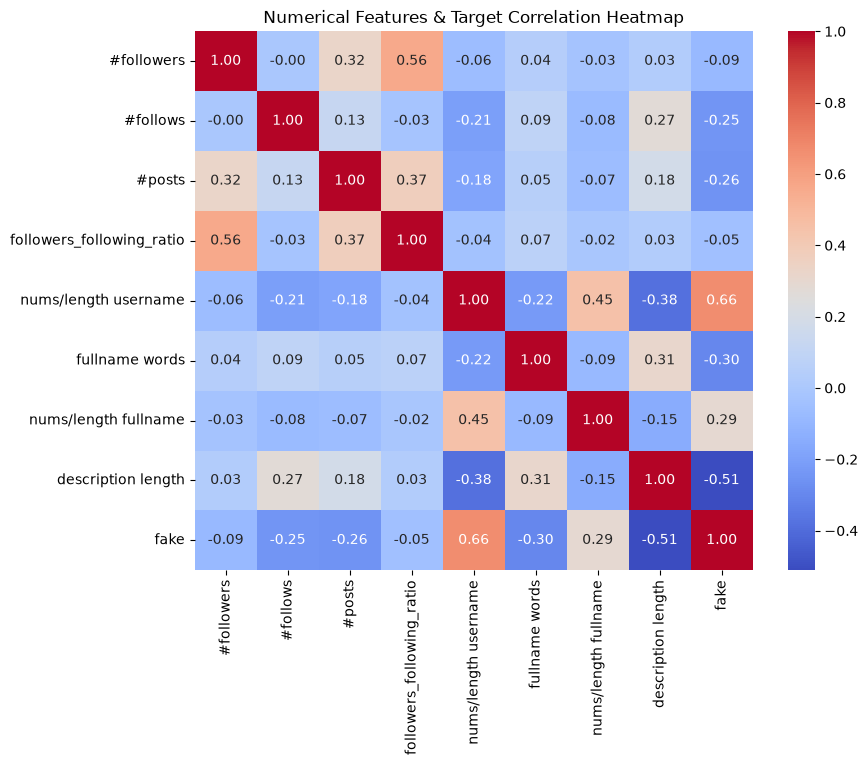

In [17]:
numeric_df = df[['#followers', '#follows', '#posts', 'followers_following_ratio', 
                 'nums/length username', 'fullname words', 'nums/length fullname', 
                 'description length', 'fake']].copy()
plt.figure(figsize=(9, 7))
sn.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Numerical Features & Target Correlation Heatmap')
plt.show()

### Comparative Synthesis: Kaggle Instagram Dataset vs. LIMFADD Dataset

| Feature / Aspect | LIMFADD Dataset | Kaggle Instagram Dataset |
| :--- | :--- | :--- |
| **Target Classification** | Multi-class (4 classes: `Bot`, `Scam`, `Spam`, `Real`) | Binary (2 classes: `Real` (0), `Fake` (1)) |
| **Data Origin & Expansion** | Sourced from social platforms and expanded via LLM synthetic generation | Scraped empirical real-world Instagram user profiles |
| **Sample Size** | 15,000 samples (3,750 per class) | 5,000 samples (2,500 per class) |
| **Feature Focus** | High-level profile & social network indicators (`Mutual Friends`, `Threads`, `External Link`) | Granular username, fullname text metrics (`nums/length`, `fullname words`) alongside activity metrics (`#posts`, `#followers`, `#follows`, `followers_following_ratio`) |
| **Cleanliness & Formatting** | Mixed categorical strings (`'N'`, `'yes'`, `'Yes'`), `#DIV/0!` ratio strings requiring coercing | Clean numeric encodings (`int64`, `float64`), no null values, 66 duplicates |
| **Key Fraud Signatures** | Bot/Spam/Scam classes show distinct patterns in mutual friends and bio presence | Fake profiles heavily characterized by 0 posts (53.4%), missing profile pics (78.6%), 0 external URLs (100%), and higher username digit ratios |
